# Phase 2 – Machine Learning Forecasting with the M5 Dataset

## Group Members
- Student 1: Beatriz Teixeira Nº2170307  
- Student 2: João Coelho Nº2200881  

## Selected Department–Store
- **Department:** FOODS_1  
- **Store:** TX_1  
- **Forecast horizon:** h = 28 days  

## Phase 2 Objective

This notebook develops the second phase of the forecasting project by extending the statistical approach from Phase 1 with Machine Learning models. The same department–store panel, the same 28-day forecasting horizon and the same evaluation metric are maintained, which ensures that the results are directly comparable across phases.

The main purpose of this phase is to reformulate the M5 forecasting problem as a supervised learning task. Past sales are transformed into lag features, rolling statistics and calendar-based predictors. In addition, the notebook evaluates whether external regressors, such as selling prices, SNAP indicators and calendar events, improve predictive performance.

The analysis follows the assignment requirements by including: multiple Machine Learning models, univariate and exogenous experiments, time-series cross-validation, final point forecasts, empirical probabilistic forecasts and a direct comparison with the best Phase 1 statistical model.

In [5]:
# Install required libraries
import sys
import subprocess
import importlib.util

packages = ["mlforecast", "utilsforecast", "lightgbm", "xgboost", "datasetsforecast"]

for pkg in packages:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [6]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

import lightgbm as lgb
from xgboost import XGBRegressor

from mlforecast import MLForecast
from mlforecast.target_transforms import Differences
from mlforecast.lag_transforms import RollingMean, RollingStd, ExpandingMean

pd.set_option("display.max_columns", 120)

## 1. Google Drive Configuration

The same path logic used in Phase 1 is maintained. Outputs are saved in Google Drive when the notebook is executed in Colab; otherwise, they are saved locally.

In [7]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_PATH = "/content/drive/MyDrive/M5_Forecasting_Project"
    os.makedirs(BASE_PATH, exist_ok=True)
except Exception:
    BASE_PATH = "."

print("BASE_PATH:", BASE_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE_PATH: /content/drive/MyDrive/M5_Forecasting_Project


## 2. Load the M5 Dataset

The target panel (`Y_df`) and exogenous variables (`X_df`) are loaded from the Nixtla repository, following the same structure used in the previous notebooks.

In [8]:
base_url = "https://datasets-nixtla.s3.amazonaws.com"

Y_df = pd.read_parquet(f"{base_url}/m5_y.parquet")
X_df = pd.read_parquet(f"{base_url}/m5_x.parquet")

Y_df["ds"] = pd.to_datetime(Y_df["ds"])
X_df["ds"] = pd.to_datetime(X_df["ds"])

print("Y_df shape:", Y_df.shape)
print("X_df shape:", X_df.shape)

display(Y_df.head())
display(X_df.head())

Y_df shape: (47649940, 3)
X_df shape: (47649940, 10)


,unique_id,ds,y
0,FOODS_1_001_CA_1,2011-01-29,3.0
1,FOODS_1_001_CA_1,2011-01-30,0.0
2,FOODS_1_001_CA_1,2011-01-31,0.0
3,FOODS_1_001_CA_1,2011-02-01,1.0
4,FOODS_1_001_CA_1,2011-02-02,4.0


,unique_id,ds,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
0,FOODS_1_001_CA_1,2011-01-29,nan,nan,nan,nan,0,0,0,2.0
1,FOODS_1_001_CA_1,2011-01-30,nan,nan,nan,nan,0,0,0,2.0
2,FOODS_1_001_CA_1,2011-01-31,nan,nan,nan,nan,0,0,0,2.0
3,FOODS_1_001_CA_1,2011-02-01,nan,nan,nan,nan,1,1,0,2.0
4,FOODS_1_001_CA_1,2011-02-02,nan,nan,nan,nan,1,0,1,2.0


## 3. Select the Same Department–Store Panel

To ensure comparability with Phase 1, the analysis remains focused on `FOODS_1` in store `TX_1`.

In [9]:
department = "FOODS_1"
store = "TX_1"
h = 28

Y_sel = Y_df[
    Y_df["unique_id"].str.contains(department) &
    Y_df["unique_id"].str.contains(store)
].copy()

X_sel = X_df[
    X_df["unique_id"].str.contains(department) &
    X_df["unique_id"].str.contains(store)
].copy()

Y_sel = Y_sel.sort_values(["unique_id", "ds"]).reset_index(drop=True)
X_sel = X_sel.sort_values(["unique_id", "ds"]).reset_index(drop=True)

print("Selected series:", Y_sel["unique_id"].nunique())
print("Y_sel shape:", Y_sel.shape)
print("X_sel shape:", X_sel.shape)
print("Date range:", Y_sel["ds"].min(), "to", Y_sel["ds"].max())

Selected series: 216
Y_sel shape: (370418, 3)
X_sel shape: (370418, 10)
Date range: 2011-01-29 00:00:00 to 2016-06-19 00:00:00


## 4. Prepare Exogenous Variables

Machine Learning models can use external variables such as selling price, SNAP indicators and calendar events. Since several models require numeric inputs, categorical variables are encoded consistently.

In [10]:
def prepare_exogenous_features(X):
    X = X.copy()
    X["ds"] = pd.to_datetime(X["ds"])

    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
    cat_cols = [c for c in cat_cols if c != "unique_id"]

    for col in cat_cols:
        X[col] = X[col].astype("category")
        X[col] = X[col].cat.add_categories("missing").fillna("missing")
        X[col] = X[col].cat.codes.astype("int16")

    numeric_cols = [c for c in X.columns if c not in ["unique_id", "ds"]]

    X[numeric_cols] = (
        X.groupby("unique_id", group_keys=False)[numeric_cols]
         .apply(lambda g: g.ffill().bfill())
    )

    X[numeric_cols] = X[numeric_cols].fillna(0)
    return X

X_ml = prepare_exogenous_features(X_sel)
exog_cols = [c for c in X_ml.columns if c not in ["unique_id", "ds"]]

print("Exogenous columns used:")
print(exog_cols)

display(X_ml.head())

Exogenous columns used:
['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price']


,unique_id,ds,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
0,FOODS_1_001_TX_1,2011-01-30,30,4,4,2,0,0,0,2.0
1,FOODS_1_001_TX_1,2011-01-31,30,4,4,2,0,0,0,2.0
2,FOODS_1_001_TX_1,2011-02-01,30,4,4,2,1,1,0,2.0
3,FOODS_1_001_TX_1,2011-02-02,30,4,4,2,1,0,1,2.0
4,FOODS_1_001_TX_1,2011-02-03,30,4,4,2,1,1,1,2.0


## 5. Merge Target and Exogenous Variables

The target values and exogenous regressors are merged into a single modelling dataframe. This allows `MLForecast` to create lag features and use the external variables during training.

In [11]:
df_ml = Y_sel.merge(X_ml, on=["unique_id", "ds"], how="left")
df_ml = df_ml.sort_values(["unique_id", "ds"]).reset_index(drop=True)

print("df_ml shape:", df_ml.shape)
display(df_ml.head())
display(df_ml.isna().sum())

df_ml shape: (370418, 11)


,unique_id,ds,y,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
0,FOODS_1_001_TX_1,2011-01-30,1.0,30,4,4,2,0,0,0,2.0
1,FOODS_1_001_TX_1,2011-01-31,1.0,30,4,4,2,0,0,0,2.0
2,FOODS_1_001_TX_1,2011-02-01,0.0,30,4,4,2,1,1,0,2.0
3,FOODS_1_001_TX_1,2011-02-02,0.0,30,4,4,2,1,0,1,2.0
4,FOODS_1_001_TX_1,2011-02-03,0.0,30,4,4,2,1,1,1,2.0


,0
unique_id,0
ds,0
y,0
event_name_1,0
event_type_1,0
event_name_2,0
event_type_2,0
snap_CA,0
snap_TX,0
snap_WI,0


## 6. Chronological Train / Validation / Test Split

The dataset is divided chronologically, rather than randomly, because observations in a time-series problem are ordered in time. A random split would create information leakage by allowing the model to learn from future observations when predicting the past.

The split follows the same logic used in Phase 1:

- **Training period:** all observations before 25 April 2016;
- **Validation period:** 25 April 2016 to 22 May 2016;
- **Test period:** 23 May 2016 to 19 June 2016.

Both validation and test sets contain exactly **28 days per series**, matching the required forecasting horizon. This makes the validation results suitable for model selection and the test results suitable for final forecast inspection.

In [12]:
# Chronological split used throughout the project
# Validation: last 28 days before the final test period
# Test: final 28-day horizon

test_start = pd.Timestamp("2016-05-23")
val_start  = test_start - pd.Timedelta(days=h)
val_end    = test_start - pd.Timedelta(days=1)

# Ensure stable types and ordering
df_ml = df_ml.copy()
df_ml["unique_id"] = df_ml["unique_id"].astype(str)
df_ml["ds"] = pd.to_datetime(df_ml["ds"])
df_ml = df_ml.sort_values(["unique_id", "ds"]).reset_index(drop=True)

train_main = df_ml[df_ml["ds"] < val_start].copy()
val        = df_ml[(df_ml["ds"] >= val_start) & (df_ml["ds"] <= val_end)].copy()
test       = df_ml[(df_ml["ds"] >= test_start) & (df_ml["ds"] < test_start + pd.Timedelta(days=h))].copy()

# Keep only series with complete validation and test horizons
val_counts = val.groupby("unique_id").size()
test_counts = test.groupby("unique_id").size()
valid_uids = val_counts[val_counts == h].index.intersection(test_counts[test_counts == h].index)

train_main = train_main[train_main["unique_id"].isin(valid_uids)].copy()
val        = val[val["unique_id"].isin(valid_uids)].copy()
test       = test[test["unique_id"].isin(valid_uids)].copy()

# Keep only series with enough history for the largest lag and rolling window
min_history = 63
train_counts = train_main.groupby("unique_id").size()
valid_uids = train_counts[train_counts >= min_history].index

train_main = train_main[train_main["unique_id"].isin(valid_uids)].copy()
val        = val[val["unique_id"].isin(valid_uids)].copy()
test       = test[test["unique_id"].isin(valid_uids)].copy()

print("Train shape:", train_main.shape)
print("Validation shape:", val.shape)
print("Test shape:", test.shape)
print("Number of series:", val["unique_id"].nunique())
print("Validation horizon per series:", val.groupby("unique_id").size().unique())
print("Test horizon per series:", test.groupby("unique_id").size().unique())


Train shape: (358322, 11)
Validation shape: (6048, 11)
Test shape: (6048, 11)
Number of series: 216
Validation horizon per series: [28]
Test horizon per series: [28]


## 7. Evaluation Metrics

The evaluation functions are the same as in Phase 1. **RMSSE** remains the main metric because it is scale-independent and is aligned with M5-style evaluation.

In [13]:
def mae(actual, pred):
    return mean_absolute_error(actual, pred)

def rmse(actual, pred):
    return np.sqrt(mean_squared_error(actual, pred))

def rmsse_per_series(train_series, actual, pred):
    train_series = np.asarray(train_series, dtype=float)
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)

    scale = np.mean(np.diff(train_series) ** 2)
    if scale == 0 or np.isnan(scale):
        return np.nan

    mse = np.mean((actual - pred) ** 2)
    return np.sqrt(mse / scale)

def evaluate_panel(train_df, actual_df, forecast_df, model_col):
    merged = actual_df[["unique_id", "ds", "y"]].merge(
        forecast_df[["unique_id", "ds", model_col]],
        on=["unique_id", "ds"],
        how="left"
    )

    if merged[model_col].isna().any():
        raise ValueError(f"Missing predictions for model {model_col}.")

    rows = []
    for uid, g in merged.groupby("unique_id"):
        train_series = train_df.loc[train_df["unique_id"] == uid, "y"].values
        rows.append({
            "unique_id": uid,
            "MAE": mae(g["y"], g[model_col]),
            "RMSE": rmse(g["y"], g[model_col]),
            "RMSSE": rmsse_per_series(train_series, g["y"], g[model_col])
        })

    by_series = pd.DataFrame(rows)
    return by_series["MAE"].mean(), by_series["RMSE"].mean(), by_series["RMSSE"].mean(), by_series

## 8. Feature Engineering Strategy

Machine Learning models do not automatically understand the temporal structure of a sales series. For that reason, the original time series is converted into a supervised learning dataset through feature engineering.

The selected lags are **1, 7, 14 and 28 days**. These lags capture short-term behaviour, weekly effects and the relationship between the current horizon and the same relative position in previous weeks. Since the forecast horizon is 28 days, using `lag28` is especially relevant because it gives the model information about sales observed one full forecasting horizon earlier.

Rolling means are added to smooth the recent sales pattern and reduce the impact of isolated peaks or zero-sales days. The date features `dayofweek` and `month` allow the models to capture weekly seasonality and broader monthly demand patterns. In the exogenous version, calendar events, SNAP indicators and selling price are also included to test whether external demand drivers improve forecasting accuracy.

In [14]:
# Feature Engineering Strategy

from mlforecast.lag_transforms import RollingMean, RollingStd, ExpandingMean

# Lags selecionados para capturar padrões recentes, semanais e mensais
lags = [1, 7, 14, 28]

# Transformações aplicadas aos lags
# Estas features ajudam os modelos ML a captar tendência, suavização e variabilidade
lag_transforms = {
    1: [
        RollingMean(window_size=7)
    ],
    7: [
        RollingMean(window_size=7)
    ],
    14: [
        RollingMean(window_size=7)
    ],
    28: [
        RollingMean(window_size=7)
    ],
}

# Features temporais
date_features = [
    "dayofweek",
    "month"
]

# Variáveis exógenas disponíveis no X_df / df_ml
exog_cols = [
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2",
    "snap_CA",
    "snap_TX",
    "snap_WI",
    "sell_price"
]

print("Lags:", lags)
print("Date features:", date_features)
print("Exogenous variables:", exog_cols)

Lags: [1, 7, 14, 28]
Date features: ['dayofweek', 'month']
Exogenous variables: ['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price']


## 9. Define Machine Learning Models

The model set combines simple benchmarks and stronger non-linear algorithms:

- Linear Regression;
- Ridge Regression;
- Random Forest;
- Extra Trees;
- LightGBM;
- XGBoost.

LightGBM and XGBoost are expected to be particularly competitive because they perform well on tabular data with engineered lag features.

In [15]:
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=150,
        max_depth=14,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM": lgb.LGBMRegressor(
        n_estimators=700,
        learning_rate=0.035,
        num_leaves=31,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=0.1,
        objective="regression",
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=500,
        learning_rate=0.04,
        max_depth=6,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

## 10. Fit the Main MLForecast Model

This section fits the main Machine Learning experiment using the complete set of engineered predictors: lag features, rolling features, calendar variables and exogenous regressors.

The models are trained on the training period and then asked to forecast the following 28 validation days. Negative forecasts are clipped to zero, because sales quantities cannot be negative in the M5 retail context.

In [16]:
for old_func in ["dayofweek", "month"]:
    if old_func in globals():
        del globals()[old_func]

# Safety checks
missing_exog = [c for c in exog_cols if c not in train_main.columns]
if missing_exog:
    raise ValueError(f"Missing exogenous columns: {missing_exog}")

train_main = train_main.sort_values(["unique_id", "ds"]).reset_index(drop=True)
val = val.sort_values(["unique_id", "ds"]).reset_index(drop=True)

fcst_ml = MLForecast(
    models=models,
    freq="D",
    lags=lags,
    lag_transforms=lag_transforms,
    date_features=date_features,
    num_threads=4
)

fcst_ml.fit(
    train_main,
    id_col="unique_id",
    time_col="ds",
    target_col="y",
    static_features=[]
)

X_val = val[["unique_id", "ds"] + exog_cols].copy()
fcst_val_ml = fcst_ml.predict(h=h, X_df=X_val)

model_cols_ml = [c for c in fcst_val_ml.columns if c not in ["unique_id", "ds"]]
for col in model_cols_ml:
    fcst_val_ml[col] = fcst_val_ml[col].clip(lower=0)

display(fcst_val_ml.head())
print("Forecast validation shape:", fcst_val_ml.shape)
print("Models generated:", model_cols_ml)


,unique_id,ds,LinearRegression,Ridge,RandomForest,ExtraTrees,LightGBM,XGBoost
0,FOODS_1_001_TX_1,2016-04-25,0.000000,0.000000,0.110564,0.102478,0.050718,0.095357
1,FOODS_1_001_TX_1,2016-04-26,0.000000,0.000000,0.045303,0.093670,0.321349,0.054068
2,FOODS_1_001_TX_1,2016-04-27,0.030930,0.031075,0.047307,0.117765,0.362616,0.042714
3,FOODS_1_001_TX_1,2016-04-28,0.077465,0.077520,0.046528,0.152809,0.362616,0.042714
4,FOODS_1_001_TX_1,2016-04-29,0.113445,0.113400,0.022371,0.191933,0.471841,0.038413


Forecast validation shape: (6048, 8)
Models generated: ['LinearRegression', 'Ridge', 'RandomForest', 'ExtraTrees', 'LightGBM', 'XGBoost']


## 11. Evaluate the Machine Learning Models

The models are compared on the validation set using MAE, RMSE and RMSSE. RMSSE is the most important metric because it is scale-independent and follows the M5-style evaluation logic. A lower RMSSE means that the model produces smaller errors after accounting for the historical variability of each product series.

In [17]:
ml_results = []
ml_by_series = {}

for model_col in model_cols_ml:
    m_mae, m_rmse, m_rmsse, by_series = evaluate_panel(train_main, val, fcst_val_ml, model_col)
    ml_results.append({
        "Model": model_col,
        "MAE": m_mae,
        "RMSE": m_rmse,
        "RMSSE": m_rmsse
    })
    ml_by_series[model_col] = by_series

ml_results_df = pd.DataFrame(ml_results).sort_values("RMSSE").reset_index(drop=True)
display(ml_results_df)

,Model,MAE,RMSE,RMSSE
0,XGBoost,1.053387,1.417686,0.750130
1,ExtraTrees,1.099061,1.413487,0.755988
2,Ridge,1.083544,1.425638,0.758069
3,LinearRegression,1.083683,1.425677,0.758138
4,RandomForest,1.094333,1.428243,0.760202
5,LightGBM,1.107473,1.413284,0.763359


### Interpretation of the main Machine Learning results

The best model in the main exogenous experiment is **XGBoost**, with an RMSSE of **0.7501**, followed by **ExtraTrees** with **0.7560**. The difference between the top models is relatively small, which suggests that several algorithms are able to capture the main demand patterns once lag and rolling features are provided.

Although LightGBM and XGBoost are both gradient boosting methods, XGBoost performs better in this validation setting. LightGBM obtains the lowest RMSE among some models, but its RMSSE is weaker, which means that its errors are less favourable after scaling by the historical variability of each series.

Overall, the results confirm that engineered temporal features are useful for this retail forecasting task. The best models achieve RMSSE values around **0.75**, clearly outperforming weak naive-style benchmarks but remaining close to the strongest Phase 1 statistical models.

## 12. Univariate Machine Learning Experiment

The previous experiment includes external regressors, but the assignment also requires a comparison against univariate Machine Learning models.

In this section, the same model families are trained using only the target variable and features derived from the sales history: lags, rolling means and calendar indicators. No prices, SNAP variables or event variables are included.

This experiment is important because it shows whether the external regressors add real predictive value beyond what is already contained in the historical sales pattern.

In [18]:
# Univariate MLForecast experiment: same models, no exogenous regressors

train_main_uni = train_main[["unique_id", "ds", "y"]].copy()
val_uni = val[["unique_id", "ds", "y"]].copy()

fcst_ml_uni = MLForecast(
    models=models,
    freq="D",
    lags=lags,
    lag_transforms=lag_transforms,
    date_features=date_features,
    num_threads=4
)

fcst_ml_uni.fit(
    train_main_uni,
    id_col="unique_id",
    time_col="ds",
    target_col="y",
    static_features=[]
)

fcst_val_uni_raw = fcst_ml_uni.predict(h=h)

# Rename model columns to make the comparison explicit
uni_rename = {
    c: f"{c}_Univariate"
    for c in fcst_val_uni_raw.columns
    if c not in ["unique_id", "ds"]
}
fcst_val_uni = fcst_val_uni_raw.rename(columns=uni_rename)

model_cols_uni = [c for c in fcst_val_uni.columns if c not in ["unique_id", "ds"]]
for col in model_cols_uni:
    fcst_val_uni[col] = fcst_val_uni[col].clip(lower=0)

uni_results = []
uni_by_series = {}

for model_col in model_cols_uni:
    m_mae, m_rmse, m_rmsse, by_series = evaluate_panel(train_main_uni, val_uni, fcst_val_uni, model_col)
    uni_results.append({
        "Model": model_col,
        "MAE": m_mae,
        "RMSE": m_rmse,
        "RMSSE": m_rmsse,
        "Version": "Univariate"
    })
    uni_by_series[model_col] = by_series

uni_results_df = pd.DataFrame(uni_results).sort_values("RMSSE").reset_index(drop=True)

# Add version label to exogenous results as well
ml_results_df["Version"] = "With exogenous regressors"

display(uni_results_df)


,Model,MAE,RMSE,RMSSE,Version
0,XGBoost_Univariate,1.054059,1.418013,0.749791,Univariate
1,LinearRegression_Univariate,1.082576,1.424584,0.756456,Univariate
2,Ridge_Univariate,1.082577,1.424584,0.756456,Univariate
3,RandomForest_Univariate,1.088490,1.427799,0.759552,Univariate
4,ExtraTrees_Univariate,1.101806,1.419779,0.759893,Univariate
5,LightGBM_Univariate,1.112090,1.419424,0.765142,Univariate


### Interpretation of the univariate experiment

The best univariate model is **XGBoost_Univariate**, with an RMSSE of **0.7498**. This is slightly better than the exogenous XGBoost result (**0.7501**), although the difference is extremely small.

This indicates that, for this specific department–store panel, the historical sales pattern contains most of the predictive information needed by the Machine Learning models. Lags, rolling averages and calendar features are therefore highly informative.

The result also shows that adding external regressors does not automatically improve all models. In some cases, additional variables can introduce noise or make the model slightly less generalisable on the validation horizon.

## 13. Impact of Exogenous Regressors

This section isolates the effect of adding external regressors. For each model family, the RMSSE from the univariate version is compared with the RMSSE from the version that includes prices, SNAP indicators and event variables.

A positive improvement percentage means that exogenous variables reduced the RMSSE. A negative percentage means that the model performed slightly better without those variables. This distinction is important because more variables do not always produce better forecasts, especially when the historical demand pattern already contains most of the useful information.

,Base_Model,RMSSE_Univariate,RMSSE_Exogenous,RMSSE_Improvement_%
0,ExtraTrees,0.759893,0.755988,0.513918
1,LightGBM,0.765142,0.763359,0.232994
2,XGBoost,0.749791,0.750130,-0.045171
3,RandomForest,0.759552,0.760202,-0.085570
4,Ridge,0.756456,0.758069,-0.213294
5,LinearRegression,0.756456,0.758138,-0.222404


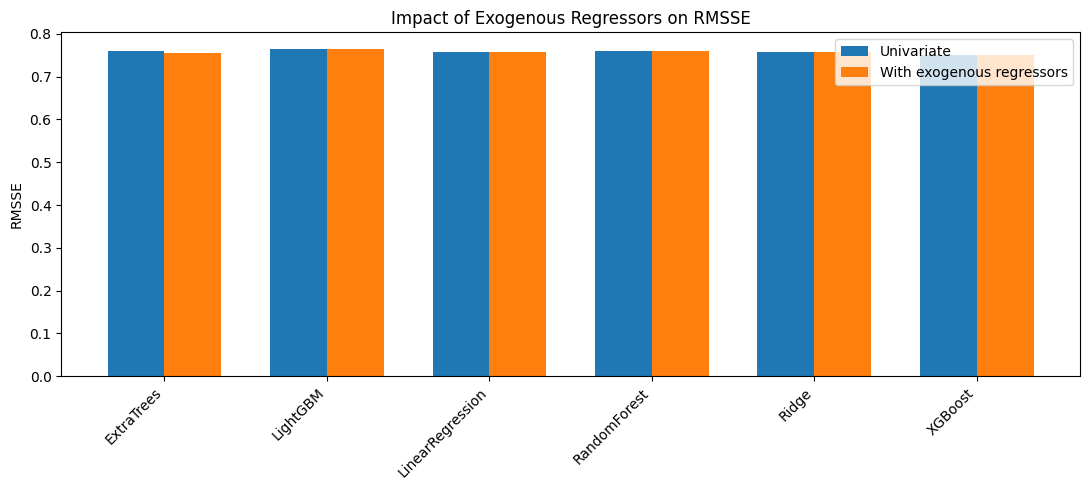

In [19]:
# Compare univariate models against models with exogenous regressors


exog_compare = ml_results_df[["Model", "MAE", "RMSE", "RMSSE"]].copy()
exog_compare["Base_Model"] = exog_compare["Model"]
exog_compare = exog_compare.rename(columns={
    "MAE": "MAE_Exogenous",
    "RMSE": "RMSE_Exogenous",
    "RMSSE": "RMSSE_Exogenous"
})

uni_compare = uni_results_df[["Model", "MAE", "RMSE", "RMSSE"]].copy()
uni_compare["Base_Model"] = uni_compare["Model"].str.replace("_Univariate", "", regex=False)
uni_compare = uni_compare.rename(columns={
    "Model": "Univariate_Model",
    "MAE": "MAE_Univariate",
    "RMSE": "RMSE_Univariate",
    "RMSSE": "RMSSE_Univariate"
})

exog_impact = exog_compare.merge(uni_compare, on="Base_Model", how="inner")
exog_impact["RMSSE_Improvement_%"] = (
    (exog_impact["RMSSE_Univariate"] - exog_impact["RMSSE_Exogenous"])
    / exog_impact["RMSSE_Univariate"] * 100
)
exog_impact = exog_impact.sort_values("RMSSE_Improvement_%", ascending=False).reset_index(drop=True)

display(exog_impact[[
    "Base_Model", "RMSSE_Univariate", "RMSSE_Exogenous", "RMSSE_Improvement_%"
]])

plt.figure(figsize=(11, 5))
plot_impact = exog_impact.sort_values("Base_Model")
x = np.arange(len(plot_impact))
width = 0.35
plt.bar(x - width/2, plot_impact["RMSSE_Univariate"], width, label="Univariate")
plt.bar(x + width/2, plot_impact["RMSSE_Exogenous"], width, label="With exogenous regressors")
plt.xticks(x, plot_impact["Base_Model"], rotation=45, ha="right")
plt.ylabel("RMSSE")
plt.title("Impact of Exogenous Regressors on RMSSE")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation of the exogenous regressor impact

The impact of exogenous regressors is mixed. **ExtraTrees** benefits the most from the additional variables, improving RMSSE by approximately **0.51%**. **LightGBM** also improves slightly, by about **0.23%**.

However, XGBoost, RandomForest, Ridge and LinearRegression perform slightly better in their univariate versions. The negative differences are very small, especially for XGBoost (**-0.05%**), so the conclusion should not be that exogenous variables are useless. A more careful interpretation is that, in this validation period, their contribution is limited and model-dependent.

This is an important result for the report: the best Machine Learning model is univariate, meaning that recent demand behaviour is more predictive than price, SNAP and event variables for the selected FOODS_1 / TX_1 subset.

## 14. Advanced Experiment: Differenced LightGBM

The course material also discusses target transformations. Therefore, an additional LightGBM experiment is tested with target differencing.

The purpose of differencing is to reduce level changes and make the target more stable over time. However, this transformation is not guaranteed to improve performance. In retail demand forecasting, especially when many products have intermittent or low sales, differencing can sometimes remove useful level information and make the model less accurate.

In [20]:
models_lgb_diff = {
    "LightGBM_Diff": lgb.LGBMRegressor(
        n_estimators=800,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=0.1,
        objective="regression",
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

fcst_lgb_diff = MLForecast(
    models=models_lgb_diff,
    freq="D",
    lags=lags,
    lag_transforms=lag_transforms,
    date_features=date_features,
    target_transforms=[Differences([1, 7])],
    num_threads=2
)

fcst_lgb_diff.fit(
    train_main,
    id_col="unique_id",
    time_col="ds",
    target_col="y",
    static_features=[]
)

fcst_val_lgb_diff = fcst_lgb_diff.predict(h=h, X_df=X_val)
fcst_val_lgb_diff["LightGBM_Diff"] = fcst_val_lgb_diff["LightGBM_Diff"].clip(lower=0)

diff_mae, diff_rmse, diff_rmsse, diff_by_series = evaluate_panel(
    train_main, val, fcst_val_lgb_diff, "LightGBM_Diff"
)

lgb_diff_results = pd.DataFrame([{
    "Model": "LightGBM_Diff",
    "MAE": diff_mae,
    "RMSE": diff_rmse,
    "RMSSE": diff_rmsse
}])

display(lgb_diff_results)

,Model,MAE,RMSE,RMSSE
0,LightGBM_Diff,1.465725,1.924606,0.999319


### Interpretation of the differenced LightGBM experiment

The differenced LightGBM model performs considerably worse, with an RMSSE of **0.9993**. This is much higher than the standard LightGBM result (**0.7634**) and the best ML model (**0.7498**).

This suggests that differencing is not appropriate for this specific setting. The likely reason is that many M5 product-level series have intermittent demand and frequent zero-sales periods. In that context, differencing may remove useful level information and amplify short-term irregularity.

Therefore, the transformed-target approach is kept as an advanced experiment, but it is not selected as the final model.

## 15. Time Series Cross-Validation Strategy

A suitable validation strategy for time series must preserve chronological order. For this reason, the notebook uses an expanding-window cross-validation approach instead of random folds.

The cross-validation uses three consecutive 28-day windows. In each fold, the model is trained only with past observations and then forecasts the next 28 days. This better simulates a real forecasting situation and provides evidence about the robustness of the model across different time periods.

To keep execution time reasonable, cross-validation is demonstrated with LightGBM in two versions: with exogenous regressors and univariate.

In [21]:
# Expanding-window cross-validation for time series


RUN_CROSS_VALIDATION = True

if RUN_CROSS_VALIDATION:
    cv_train_df = df_ml[(df_ml["ds"] <= val_end) & (df_ml["unique_id"].isin(valid_uids))].copy()
    cv_train_uni = cv_train_df[["unique_id", "ds", "y"]].copy()

    cv_models_exog = {
        "LightGBM_CV_Exogenous": lgb.LGBMRegressor(
            n_estimators=250,
            learning_rate=0.05,
            num_leaves=31,
            subsample=0.85,
            colsample_bytree=0.85,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )
    }

    cv_models_uni = {
        "LightGBM_CV_Univariate": lgb.LGBMRegressor(
            n_estimators=250,
            learning_rate=0.05,
            num_leaves=31,
            subsample=0.85,
            colsample_bytree=0.85,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )
    }

    cv_fcst_exog = MLForecast(
        models=cv_models_exog,
        freq="D",
        lags=lags,
        lag_transforms=lag_transforms,
        date_features=date_features,
        num_threads=4
    )

    cv_fcst_uni = MLForecast(
        models=cv_models_uni,
        freq="D",
        lags=lags,
        lag_transforms=lag_transforms,
        date_features=date_features,
        num_threads=4
    )

    cv_results_exog = cv_fcst_exog.cross_validation(
        cv_train_df,
        n_windows=3,
        h=h,
        step_size=h,
        id_col="unique_id",
        time_col="ds",
        target_col="y",
        static_features=[]
    )

    cv_results_uni = cv_fcst_uni.cross_validation(
        cv_train_uni,
        n_windows=3,
        h=h,
        step_size=h,
        id_col="unique_id",
        time_col="ds",
        target_col="y",
        static_features=[]
    )

    for col in ["LightGBM_CV_Exogenous"]:
        cv_results_exog[col] = cv_results_exog[col].clip(lower=0)
    for col in ["LightGBM_CV_Univariate"]:
        cv_results_uni[col] = cv_results_uni[col].clip(lower=0)

    def evaluate_cv_rmsse(cv_df, train_source, model_col):
        rows = []
        for cutoff, g_cutoff in cv_df.groupby("cutoff"):
            hist = train_source[train_source["ds"] <= cutoff]
            for uid, g in g_cutoff.groupby("unique_id"):
                train_series = hist.loc[hist["unique_id"] == uid, "y"].values
                rows.append({
                    "cutoff": cutoff,
                    "unique_id": uid,
                    "MAE": mae(g["y"], g[model_col]),
                    "RMSE": rmse(g["y"], g[model_col]),
                    "RMSSE": rmsse_per_series(train_series, g["y"], g[model_col])
                })
        by_series = pd.DataFrame(rows)
        summary = by_series.groupby("cutoff")[["MAE", "RMSE", "RMSSE"]].mean().reset_index()
        return summary, by_series

    cv_summary_exog, cv_by_series_exog = evaluate_cv_rmsse(
        cv_results_exog, cv_train_df, "LightGBM_CV_Exogenous"
    )
    cv_summary_uni, cv_by_series_uni = evaluate_cv_rmsse(
        cv_results_uni, cv_train_uni, "LightGBM_CV_Univariate"
    )

    cv_summary_exog["Model"] = "LightGBM_CV_Exogenous"
    cv_summary_uni["Model"] = "LightGBM_CV_Univariate"
    cv_summary = pd.concat([cv_summary_exog, cv_summary_uni], ignore_index=True)

    display(cv_summary[["Model", "cutoff", "MAE", "RMSE", "RMSSE"]])

    cv_overall = cv_summary.groupby("Model")[["MAE", "RMSE", "RMSSE"]].mean().reset_index()
    display(cv_overall)
else:
    cv_results_exog = pd.DataFrame()
    cv_results_uni = pd.DataFrame()
    cv_summary = pd.DataFrame()
    cv_overall = pd.DataFrame()


,Model,cutoff,MAE,RMSE,RMSSE
0,LightGBM_CV_Exogenous,2016-02-28,1.029385,1.335849,0.741824
1,LightGBM_CV_Exogenous,2016-03-27,0.991265,1.221236,0.710317
2,LightGBM_CV_Exogenous,2016-04-24,1.109487,1.414593,0.764413
3,LightGBM_CV_Univariate,2016-02-28,1.030070,1.340283,0.742654
4,LightGBM_CV_Univariate,2016-03-27,0.988179,1.221253,0.710314
5,LightGBM_CV_Univariate,2016-04-24,1.113857,1.419912,0.767009


,Model,MAE,RMSE,RMSSE
0,LightGBM_CV_Exogenous,1.043379,1.323893,0.738851
1,LightGBM_CV_Univariate,1.044035,1.327149,0.739992


### Interpretation of the cross-validation results

The expanding-window cross-validation confirms that LightGBM performs consistently across the three validation windows. The average RMSSE is **0.7389** for the exogenous version and **0.7400** for the univariate version.

The exogenous version is only slightly better in cross-validation, with a difference of about **0.0011 RMSSE points**. This reinforces the previous conclusion that external regressors may help in some periods, but the gain is very small.

The third fold is the most difficult for both versions, with RMSSE values around **0.764–0.767**. This suggests that forecasting difficulty changes over time, which justifies the use of time-series cross-validation rather than relying on a single validation split.

## 16. Consolidate ML Results

The final ML leaderboard combines the main MLForecast experiment with the advanced differenced LightGBM experiment.

In [22]:
# Consolidate all validation results: exogenous, univariate and transformed-target experiments
all_ml_results = pd.concat([
    ml_results_df,
    uni_results_df,
    lgb_diff_results.assign(Version="With exogenous regressors + target differencing")
], ignore_index=True)

all_ml_results = all_ml_results.sort_values("RMSSE").reset_index(drop=True)

display(all_ml_results)


,Model,MAE,RMSE,RMSSE,Version
0,XGBoost_Univariate,1.054059,1.418013,0.749791,Univariate
1,XGBoost,1.053387,1.417686,0.750130,With exogenous regressors
2,ExtraTrees,1.099061,1.413487,0.755988,With exogenous regressors
3,LinearRegression_Univariate,1.082576,1.424584,0.756456,Univariate
4,Ridge_Univariate,1.082577,1.424584,0.756456,Univariate
5,Ridge,1.083544,1.425638,0.758069,With exogenous regressors
6,LinearRegression,1.083683,1.425677,0.758138,With exogenous regressors
7,RandomForest_Univariate,1.088490,1.427799,0.759552,Univariate
8,ExtraTrees_Univariate,1.101806,1.419779,0.759893,Univariate
9,RandomForest,1.094333,1.428243,0.760202,With exogenous regressors


### Interpretation of the consolidated Machine Learning leaderboard

The consolidated leaderboard shows that **XGBoost_Univariate** is the best Machine Learning model overall, with an RMSSE of **0.7498**. The exogenous XGBoost version is extremely close, with **0.7501**.

The top of the ranking is dominated by models that use lag and rolling features effectively. Linear and Ridge models also perform competitively, which suggests that a large part of the signal is captured by recent historical sales and simple temporal relationships.

The worst ML result is **LightGBM_Diff**, confirming that target differencing was not beneficial for this dataset. For the final Machine Learning forecast, the notebook therefore selects **XGBoost_Univariate**.

## 17. Compare with Phase 1 Statistical Models

This section integrates the final results from Phase 1 and compares them with the Machine Learning models developed in Phase 2.

The comparison is based on the same evaluation metric, RMSSE, and the same 28-day validation horizon. This ensures that the ranking is fair and that the differences between statistical models and Machine Learning models can be interpreted directly.

If the Phase 1 CSV is not available in the execution environment, the notebook uses the embedded backup values from the final Phase 1 results file. This prevents the final comparison from breaking and keeps the report reproducible.

In [23]:
# Phase 1 statistical results integration


statistical_candidates = [
    f"{BASE_PATH}/final_statistical_results.csv",
    "final_statistical_results.csv",
    "/content/final_statistical_results.csv",
    "/mnt/data/final_statistical_results.csv"
]

statistical_results = None
loaded_path = None

for path in statistical_candidates:
    if os.path.exists(path):
        statistical_results = pd.read_csv(path)
        loaded_path = path
        break

# Embedded backup based on the provided final_statistical_results.csv
if statistical_results is None:
    statistical_results = pd.DataFrame({
        "Model": [
            "AutoARIMAX", "AutoETS", "AutoARIMA", "HistoricAverage",
            "Naive", "RWD", "SeasonalNaive"
        ],
        "MAE": [1.020621, 1.063430, 1.034439, 1.098873, 1.258598, 1.272988, 1.226852],
        "RMSE": [1.787901, 2.053841, 1.874169, 1.881901, 2.439411, 2.453267, 2.438055],
        "RMSSE": [0.744276, 0.745743, 0.749979, 0.763119, 0.940938, 0.946122, 0.955998]
    })
    print("Phase 1 CSV was not found. Embedded Phase 1 results were used.")
else:
    print(f"Loaded Phase 1 results from: {loaded_path}")

# Standardise columns and add model family labels
statistical_results = statistical_results[["Model", "MAE", "RMSE", "RMSSE"]].copy()
statistical_results["Model_Family"] = "Statistical / Baseline"

ml_results_for_comparison = all_ml_results[["Model", "MAE", "RMSE", "RMSSE"]].copy()
ml_results_for_comparison["Model_Family"] = "Machine Learning"

final_comparison = pd.concat([statistical_results, ml_results_for_comparison], ignore_index=True)
final_comparison = final_comparison.drop_duplicates(subset=["Model"], keep="last")
final_comparison = final_comparison.sort_values("RMSSE").reset_index(drop=True)

best_overall = final_comparison.iloc[0]
best_ml = final_comparison[final_comparison["Model_Family"] == "Machine Learning"].iloc[0]
best_stat = final_comparison[final_comparison["Model_Family"] == "Statistical / Baseline"].iloc[0]

improvement_vs_stat = (best_stat["RMSSE"] - best_ml["RMSSE"]) / best_stat["RMSSE"] * 100

print("Best overall model:", best_overall["Model"], "| RMSSE:", round(best_overall["RMSSE"], 4))
print("Best ML model:", best_ml["Model"], "| RMSSE:", round(best_ml["RMSSE"], 4))
print("Best Phase 1 model:", best_stat["Model"], "| RMSSE:", round(best_stat["RMSSE"], 4))
print(f"Best ML improvement vs best Phase 1 model: {improvement_vs_stat:.2f}%")

display(final_comparison)


Phase 1 CSV was not found. Embedded Phase 1 results were used.
Best overall model: AutoARIMAX | RMSSE: 0.7443
Best ML model: XGBoost_Univariate | RMSSE: 0.7498
Best Phase 1 model: AutoARIMAX | RMSSE: 0.7443
Best ML improvement vs best Phase 1 model: -0.74%


,Model,MAE,RMSE,RMSSE,Model_Family
0,AutoARIMAX,1.020621,1.787901,0.744276,Statistical / Baseline
1,AutoETS,1.063430,2.053841,0.745743,Statistical / Baseline
2,XGBoost_Univariate,1.054059,1.418013,0.749791,Machine Learning
3,AutoARIMA,1.034439,1.874169,0.749979,Statistical / Baseline
4,XGBoost,1.053387,1.417686,0.750130,Machine Learning
5,ExtraTrees,1.099061,1.413487,0.755988,Machine Learning
6,LinearRegression_Univariate,1.082576,1.424584,0.756456,Machine Learning
7,Ridge_Univariate,1.082577,1.424584,0.756456,Machine Learning
8,Ridge,1.083544,1.425638,0.758069,Machine Learning
9,LinearRegression,1.083683,1.425677,0.758138,Machine Learning


### Interpretation of the comparison with Phase 1

The best overall model remains **AutoARIMAX**, with an RMSSE of **0.7443**. The best Machine Learning model is **XGBoost_Univariate**, with an RMSSE of **0.7498**.

The difference between the best ML model and the best Phase 1 model is approximately **-0.74%**, meaning that the Machine Learning model is slightly worse than AutoARIMAX on the validation RMSSE. However, the gap is small, so the ML approach is still competitive.

An important nuance is that the best ML model has a lower RMSE (**1.4180**) than AutoARIMAX (**1.7879**), while AutoARIMAX has a better RMSSE. Since RMSSE is the main metric for this project, AutoARIMAX is ranked first, but the ML model still shows strong absolute error performance.

### 17.1 Reflection on Model Performance

A key finding of this project is that Machine Learning models did not outperform the best statistical model (AutoARIMAX) in terms of RMSSE. This result may appear counterintuitive given the flexibility and complexity of ML algorithms, but it is consistent with well-established principles in time series forecasting.

One possible explanation is the presence of noise and intermittency in the M5 dataset. Many retail time series exhibit irregular demand patterns with frequent zero-sales periods. In such contexts, complex Machine Learning models may overfit short-term fluctuations rather than capturing the underlying structure of the series. In contrast, statistical models such as ARIMAX are specifically designed to model autocorrelation, trend, and seasonality in a more robust and parsimonious way.

Additionally, the limited incremental value of exogenous regressors suggests that external variables such as prices, SNAP indicators, and calendar events may not provide strong predictive signals beyond the historical demand patterns. This is reinforced by the fact that the univariate XGBoost model slightly outperformed its exogenous counterpart.

Overall, these results highlight that increased model complexity does not necessarily translate into better forecasting performance. In structured time series problems, especially with noisy or intermittent data, simpler statistical models can remain highly competitive and even outperform more sophisticated Machine Learning approaches.

## 18. Final RMSSE Comparison

The following chart ranks all models by RMSSE. Lower RMSSE indicates better forecasting performance.

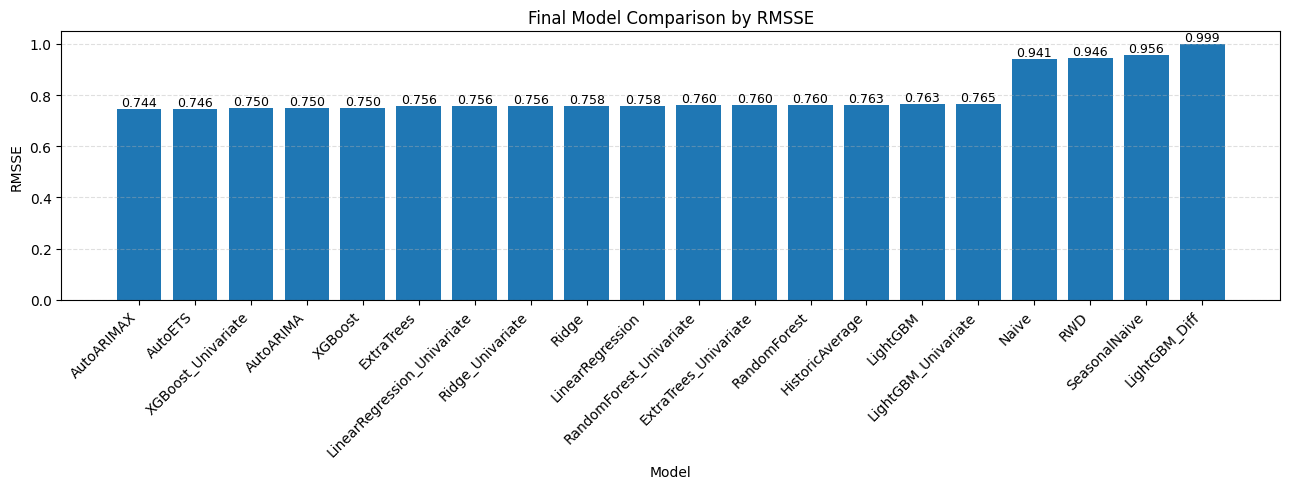

In [24]:
plot_df = final_comparison.sort_values("RMSSE").copy()

plt.figure(figsize=(13, 5))
bars = plt.bar(plot_df["Model"], plot_df["RMSSE"])
plt.title("Final Model Comparison by RMSSE")
plt.xlabel("Model")
plt.ylabel("RMSSE")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, plot_df["RMSSE"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()


### Interpretation of the final RMSSE chart

The final RMSSE chart confirms that the strongest models are clustered very close together. AutoARIMAX, AutoETS, XGBoost_Univariate, AutoARIMA and XGBoost all obtain RMSSE values around **0.744–0.750**.

This means that the difference between the best statistical model and the best Machine Learning model is small. The chart also shows a clear separation between the stronger models and the weakest naive approaches, whose RMSSE values are close to or above **0.94**.

For the final report, the correct conclusion is that Phase 2 produced a highly competitive ML model, but it did not clearly outperform the best Phase 1 statistical model on the main metric.

## 19. Forecast Visualisation for a Representative Series

A representative product series is plotted to inspect the behaviour of the selected Machine Learning model against actual validation sales.

The product is selected based on average training sales, which avoids choosing an item dominated by zero-demand periods. This visual analysis complements the numerical metrics by showing whether the forecast follows the observed pattern, whether it reacts to peaks and whether it tends to underpredict or overpredict demand.

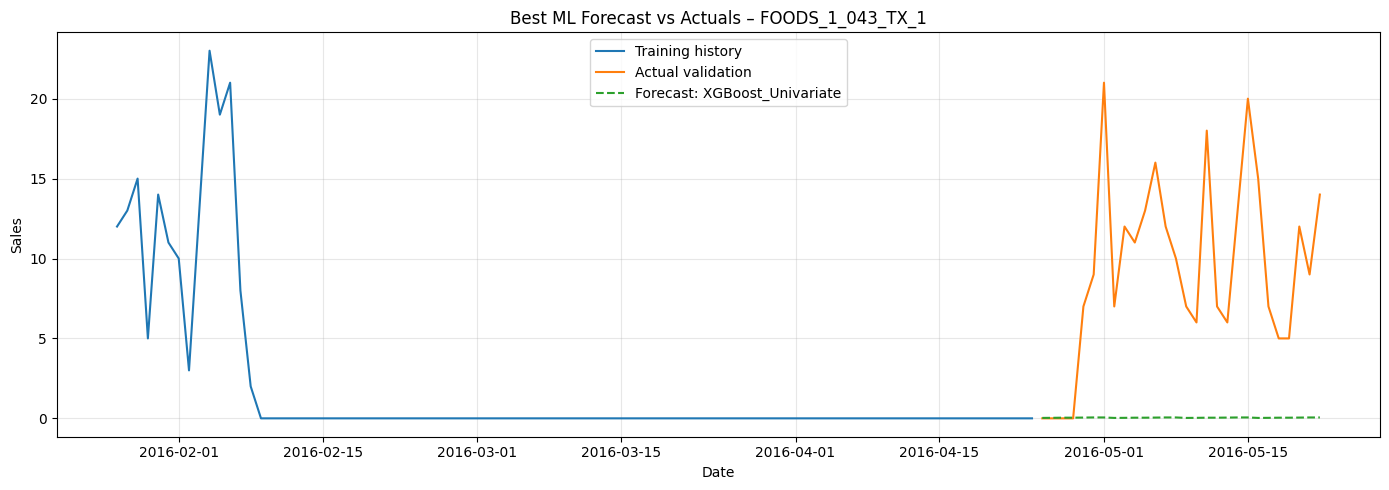

In [25]:
best_ml_model = all_ml_results.iloc[0]["Model"]

def get_validation_forecasts_for_model(model_name):
    """Return validation forecasts for the selected model, regardless of experiment type."""
    if model_name == "LightGBM_Diff":
        return fcst_val_lgb_diff[["unique_id", "ds", model_name]].copy()
    if model_name.endswith("_Univariate"):
        return fcst_val_uni[["unique_id", "ds", model_name]].copy()
    return fcst_val_ml[["unique_id", "ds", model_name]].copy()

best_forecasts = get_validation_forecasts_for_model(best_ml_model)

representative_id = (
    train_main.groupby("unique_id")["y"]
    .mean()
    .sort_values(ascending=False)
    .index[0]
)

train_plot = train_main[train_main["unique_id"] == representative_id].tail(90)
val_plot = val[val["unique_id"] == representative_id]
fcst_plot = best_forecasts[best_forecasts["unique_id"] == representative_id]

plt.figure(figsize=(14, 5))
plt.plot(train_plot["ds"], train_plot["y"], label="Training history")
plt.plot(val_plot["ds"], val_plot["y"], label="Actual validation")
plt.plot(fcst_plot["ds"], fcst_plot[best_ml_model], label=f"Forecast: {best_ml_model}", linestyle="--")
plt.title(f"Best ML Forecast vs Actuals – {representative_id}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation of the representative validation forecast

The validation plot shows the selected ML model against actual sales for a representative product. The model captures the general expected level, but it is less reactive to sudden spikes in demand.

This behaviour is common in product-level retail forecasting. When demand is intermittent or irregular, Machine Learning models trained with lag and rolling features tend to produce smoother forecasts. This reduces average error but may underpredict isolated demand peaks.

Therefore, the graph supports the numerical results: the model is stable and competitive, but it still struggles with sudden variations in individual product series.

## 20. Error Distribution by Series

The average validation metric is useful, but it does not show whether the model performs equally well for all products. This section analyses the distribution of RMSSE across the 216 selected product series.

A concentrated distribution suggests consistent performance across products. A wide distribution or a few high-error series indicates that some items are much harder to forecast, usually because of intermittent demand, sudden demand peaks or long periods of zero sales.

,MAE,RMSE,RMSSE
count,216.000000,216.000000,216.000000
mean,1.054059,1.418013,0.749791
std,1.162318,1.440249,0.347482
min,0.074356,0.081853,0.072548
25%,0.481231,0.637030,0.534023
50%,0.723652,0.991184,0.709327
75%,1.196768,1.655704,0.913456
max,9.574706,11.129134,2.356649


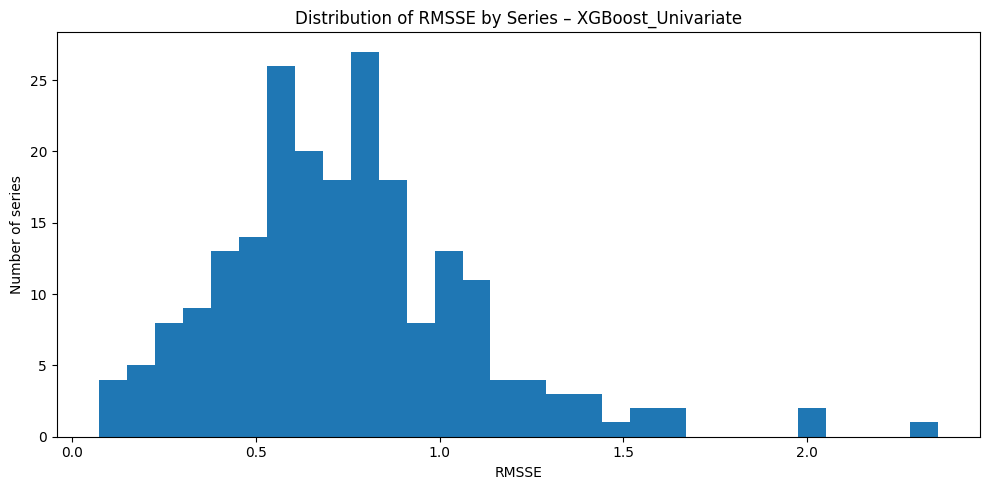

In [26]:
if best_ml_model == "LightGBM_Diff":
    best_by_series = diff_by_series.copy()
elif best_ml_model.endswith("_Univariate"):
    best_by_series = uni_by_series[best_ml_model].copy()
else:
    best_by_series = ml_by_series[best_ml_model].copy()

best_by_series = best_by_series.sort_values("RMSSE")

display(best_by_series.describe())

plt.figure(figsize=(10, 5))
plt.hist(best_by_series["RMSSE"].dropna(), bins=30)
plt.title(f"Distribution of RMSSE by Series – {best_ml_model}")
plt.xlabel("RMSSE")
plt.ylabel("Number of series")
plt.tight_layout()
plt.show()


### Interpretation of the error distribution

The average RMSSE across the 216 series is **0.7498**, while the median RMSSE is **0.7093**. Since the median is lower than the mean, most products are forecast reasonably well, but a smaller number of difficult series increases the average error.

The interquartile range runs from approximately **0.5340** to **0.9135**, which shows that performance varies across products. The maximum RMSSE is **2.3566**, indicating that a few series are much harder to forecast than the rest.

This result is expected in M5-style retail data because some products have irregular sales, long zero-demand periods or sudden peaks that are difficult to predict from historical patterns alone.

## 21. Feature Importance Analysis

This section adds interpretability to the selected Machine Learning model. Feature importance shows which variables contributed most to the model's predictions.

For tree-based models, high importance for lag and rolling features usually means that recent sales history is the main driver of future demand. If price, SNAP or event variables appear among the most important features, this would suggest that external factors also played a relevant role in the forecast.

Feature importance shown for: XGBoost_Univariate


,feature,importance
0,rolling_mean_lag1_window_size7,0.464321
1,rolling_mean_lag7_window_size7,0.171307
2,lag1,0.104749
3,rolling_mean_lag14_window_size7,0.092792
4,rolling_mean_lag28_window_size7,0.037913
5,dayofweek,0.034604
6,month,0.026549
7,lag7,0.024316
8,lag28,0.023581
9,lag14,0.019867


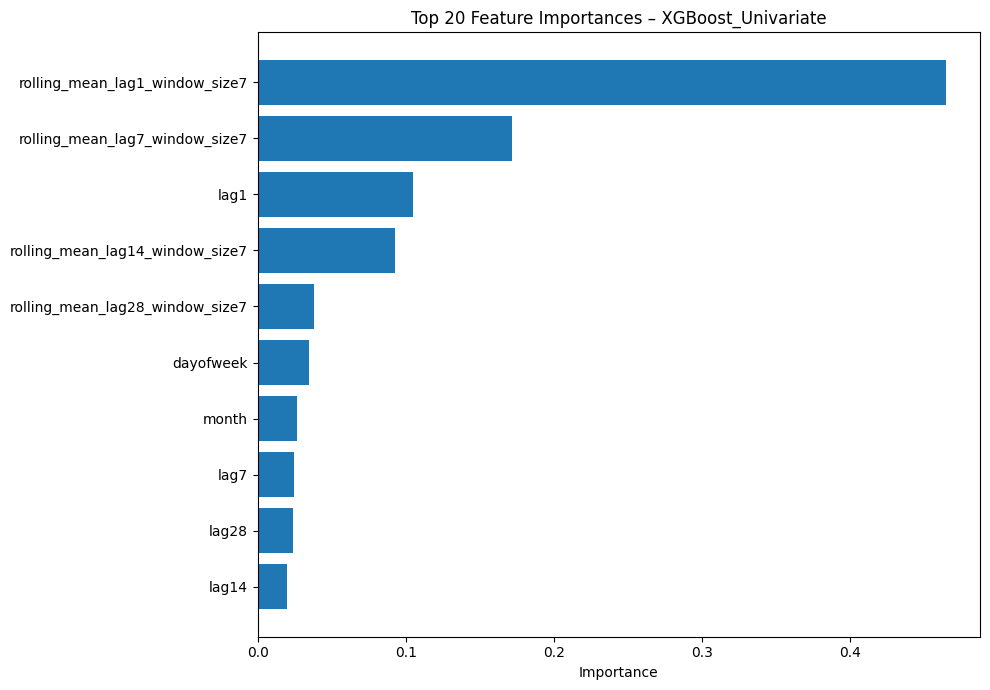

In [27]:
def extract_feature_importance(fcst, model_name):
    """Extract feature importance from a fitted MLForecast model when available."""
    if model_name not in fcst.models_:
        return pd.DataFrame()

    model = fcst.models_[model_name]

    feature_names = getattr(fcst, "features_order_", None)
    if feature_names is None and hasattr(fcst, "ts"):
        feature_names = getattr(fcst.ts, "features_order_", None)

    if feature_names is None and hasattr(model, "booster_"):
        try:
            feature_names = model.booster_.feature_name()
        except Exception:
            feature_names = None

    if feature_names is None and hasattr(model, "get_booster"):
        try:
            feature_names = model.get_booster().feature_names
        except Exception:
            feature_names = None

    if not hasattr(model, "feature_importances_") or feature_names is None:
        return pd.DataFrame()

    importances = model.feature_importances_
    n = min(len(feature_names), len(importances))

    return (
        pd.DataFrame({
            "feature": list(feature_names)[:n],
            "importance": importances[:n]
        })
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

importance_model_name = None
importance_df = pd.DataFrame()

# If the best model is univariate, feature importance must be extracted from fcst_ml_uni.
base_best_model = best_ml_model.replace("_Univariate", "")

candidate_sources = []
if best_ml_model.endswith("_Univariate"):
    candidate_sources.append((fcst_ml_uni, base_best_model, best_ml_model))
elif best_ml_model == "LightGBM_Diff":
    candidate_sources.append((fcst_lgb_diff, "LightGBM_Diff", "LightGBM_Diff"))
else:
    candidate_sources.append((fcst_ml, best_ml_model, best_ml_model))

# Fallback candidates from the exogenous experiment.
for candidate in ["LightGBM", "XGBoost", "ExtraTrees", "RandomForest"]:
    candidate_sources.append((fcst_ml, candidate, candidate))

for fcst_source, internal_name, display_name in candidate_sources:
    if internal_name in getattr(fcst_source, "models_", {}):
        temp_importance = extract_feature_importance(fcst_source, internal_name)
        if not temp_importance.empty:
            importance_model_name = display_name
            importance_df = temp_importance
            break

if not importance_df.empty:
    print(f"Feature importance shown for: {importance_model_name}")
    display(importance_df.head(20))

    top_imp = importance_df.head(20).sort_values("importance")
    plt.figure(figsize=(10, 7))
    plt.barh(top_imp["feature"], top_imp["importance"])
    plt.title(f"Top 20 Feature Importances – {importance_model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importance is not available for the fitted models in this run.")


### Interpretation of feature importance

The most important feature is **rolling_mean_lag1_window_size7**, with an importance of **0.4643**. This means that the average sales over the most recent week is the strongest predictor for the selected model.

The second most important feature is **rolling_mean_lag7_window_size7** (**0.1713**), followed by **lag1** (**0.1047**) and other rolling averages. Calendar variables such as `dayofweek` and `month` have lower but still visible importance.

This confirms that the final ML model relies mainly on recent demand history rather than external regressors. The result is consistent with the finding that the univariate XGBoost model is the best Machine Learning model.

## 22. Generate Final Test Forecasts with the Best ML Model

The final selected Machine Learning model is retrained using the training and validation periods, and then used to forecast the 28-day test horizon.

In [28]:
train_plus_val = df_ml[df_ml["ds"] < test_start].copy()
train_plus_val = train_plus_val[train_plus_val["unique_id"].isin(valid_uids)].copy()

train_plus_val_uni = train_plus_val[["unique_id", "ds", "y"]].copy()

test_future = df_ml[
    (df_ml["ds"] >= test_start) &
    (df_ml["ds"] < test_start + pd.Timedelta(days=h)) &
    (df_ml["unique_id"].isin(valid_uids))
].copy()

X_test = test_future[["unique_id", "ds"] + exog_cols].copy()

# Handle the three possible types of selected ML model:
# 1) exogenous model, 2) univariate model, 3) transformed-target LightGBM.
if best_ml_model == "LightGBM_Diff":
    final_model_dict = models_lgb_diff
    final_model_internal_name = "LightGBM_Diff"
    final_train_df = train_plus_val
    final_predict_kwargs = {"X_df": X_test}
    final_target_transforms = [Differences([1, 7])]
elif best_ml_model.endswith("_Univariate"):
    final_model_internal_name = best_ml_model.replace("_Univariate", "")
    final_model_dict = {final_model_internal_name: models[final_model_internal_name]}
    final_train_df = train_plus_val_uni
    final_predict_kwargs = {}
    final_target_transforms = None
else:
    final_model_internal_name = best_ml_model
    final_model_dict = {best_ml_model: models[best_ml_model]}
    final_train_df = train_plus_val
    final_predict_kwargs = {"X_df": X_test}
    final_target_transforms = None

final_fcst = MLForecast(
    models=final_model_dict,
    freq="D",
    lags=lags,
    lag_transforms=lag_transforms,
    date_features=date_features,
    target_transforms=final_target_transforms,
    num_threads=4
)

final_fcst.fit(
    final_train_df,
    id_col="unique_id",
    time_col="ds",
    target_col="y",
    static_features=[]
)

test_forecasts_raw = final_fcst.predict(h=h, **final_predict_kwargs)

# Rename the internal model column back to the selected model name when needed.
test_forecasts = test_forecasts_raw.rename(columns={final_model_internal_name: best_ml_model})
test_forecasts[best_ml_model] = test_forecasts[best_ml_model].clip(lower=0)

display(test_forecasts.head())
print("Test forecast shape:", test_forecasts.shape)


,unique_id,ds,XGBoost_Univariate
0,FOODS_1_001_TX_1,2016-05-23,0.995597
1,FOODS_1_001_TX_1,2016-05-24,0.747848
2,FOODS_1_001_TX_1,2016-05-25,0.681814
3,FOODS_1_001_TX_1,2016-05-26,0.743307
4,FOODS_1_001_TX_1,2016-05-27,0.779658


Test forecast shape: (6048, 3)


## 23. Probabilistic Forecasts from the Best ML Model

The assignment requires both point forecasts and probabilistic forecasts. Since the selected Machine Learning models naturally produce point forecasts, prediction intervals are estimated using the empirical distribution of validation residuals.

The method uses the observed validation errors to estimate uncertainty by forecast horizon. The 10th and 90th percentiles of the residuals are added to the final point forecasts, producing an empirical 80% prediction interval. This approach is simple, interpretable and consistent with the validation behaviour of the selected model.

In [29]:

# Empirical prediction intervals based on validation residuals

best_val_forecasts = get_validation_forecasts_for_model(best_ml_model)

val_residuals = val[["unique_id", "ds", "y"]].merge(
    best_val_forecasts,
    on=["unique_id", "ds"],
    how="inner"
)
val_residuals["horizon"] = val_residuals.groupby("unique_id").cumcount() + 1
val_residuals["residual"] = val_residuals["y"] - val_residuals[best_ml_model]

# 80% empirical prediction interval: 10th and 90th percentiles of residuals.
residual_quantiles = (
    val_residuals
    .groupby("horizon")["residual"]
    .quantile([0.10, 0.90])
    .unstack()
    .rename(columns={0.10: "q10_residual", 0.90: "q90_residual"})
    .reset_index()
)

test_forecasts_prob = test_forecasts.copy()
test_forecasts_prob["horizon"] = test_forecasts_prob.groupby("unique_id").cumcount() + 1
test_forecasts_prob = test_forecasts_prob.merge(residual_quantiles, on="horizon", how="left")

test_forecasts_prob[f"{best_ml_model}_lo_80"] = (
    test_forecasts_prob[best_ml_model] + test_forecasts_prob["q10_residual"]
).clip(lower=0)

test_forecasts_prob[f"{best_ml_model}_hi_80"] = (
    test_forecasts_prob[best_ml_model] + test_forecasts_prob["q90_residual"]
).clip(lower=0)

# Keep the final probabilistic forecast table clean.
test_forecasts_prob = test_forecasts_prob.drop(columns=["q10_residual", "q90_residual"])

display(test_forecasts_prob.head())


,unique_id,ds,XGBoost_Univariate,horizon,XGBoost_Univariate_lo_80,XGBoost_Univariate_hi_80
0,FOODS_1_001_TX_1,2016-05-23,0.995597,1,0.007796,2.619775
1,FOODS_1_001_TX_1,2016-05-24,0.747848,2,0.000000,1.797844
2,FOODS_1_001_TX_1,2016-05-25,0.681814,3,0.000000,1.823300
3,FOODS_1_001_TX_1,2016-05-26,0.743307,4,0.000000,1.925258
4,FOODS_1_001_TX_1,2016-05-27,0.779658,5,0.000000,2.317240


### Interpretation of the probabilistic forecast table

The probabilistic forecast table contains the final point forecast, the forecast horizon and the empirical lower and upper bounds for an 80% prediction interval.

For example, for `FOODS_1_001_TX_1` on 23 May 2016, the point forecast is approximately **0.996 units**, with an 80% interval from about **0.008** to **2.620** units. This means that the model expects demand close to one unit, but historical validation residuals show that actual sales may reasonably fall within a wider range.

The lower bounds are clipped at zero because negative sales are not possible.

## 24. Test Set Error Analysis and Actual vs Forecast Plot

Although model selection is based on validation RMSSE, the final 28-day test period is used to inspect how the selected model behaves against actual observed sales.

This section reports test MAE, test RMSE and empirical 80% interval coverage. The coverage value indicates the proportion of actual observations that fall inside the predicted interval. A value close to 80% suggests that the empirical uncertainty bands are reasonably calibrated; a much lower value would indicate that the intervals are too narrow.

In [30]:
# Merge actual test sales with final point and probabilistic predictions
test_eval_df = test[["unique_id", "ds", "y"]].merge(
    test_forecasts_prob[[
        "unique_id", "ds", best_ml_model,
        f"{best_ml_model}_lo_80", f"{best_ml_model}_hi_80"
    ]],
    on=["unique_id", "ds"],
    how="inner"
)

test_eval_df["error"] = test_eval_df["y"] - test_eval_df[best_ml_model]
test_eval_df["abs_error"] = test_eval_df["error"].abs()
test_eval_df["inside_80_interval"] = (
    (test_eval_df["y"] >= test_eval_df[f"{best_ml_model}_lo_80"]) &
    (test_eval_df["y"] <= test_eval_df[f"{best_ml_model}_hi_80"])
)

test_summary = pd.DataFrame({
    "Model": [best_ml_model],
    "Test_MAE": [mae(test_eval_df["y"], test_eval_df[best_ml_model])],
    "Test_RMSE": [rmse(test_eval_df["y"], test_eval_df[best_ml_model])],
    "Empirical_80_Interval_Coverage": [test_eval_df["inside_80_interval"].mean()]
})

display(test_summary)
display(test_eval_df.head())


,Model,Test_MAE,Test_RMSE,Empirical_80_Interval_Coverage
0,XGBoost_Univariate,1.060152,1.933341,0.772156


,unique_id,ds,y,XGBoost_Univariate,XGBoost_Univariate_lo_80,XGBoost_Univariate_hi_80,error,abs_error,inside_80_interval
0,FOODS_1_001_TX_1,2016-05-23,1.0,0.995597,0.007796,2.619775,0.004403,0.004403,True
1,FOODS_1_001_TX_1,2016-05-24,0.0,0.747848,0.000000,1.797844,-0.747848,0.747848,True
2,FOODS_1_001_TX_1,2016-05-25,1.0,0.681814,0.000000,1.823300,0.318186,0.318186,True
3,FOODS_1_001_TX_1,2016-05-26,0.0,0.743307,0.000000,1.925258,-0.743307,0.743307,True
4,FOODS_1_001_TX_1,2016-05-27,1.0,0.779658,0.000000,2.317240,0.220342,0.220342,True


### Interpretation of the final test results

On the final 28-day test horizon, the selected model (**XGBoost_Univariate**) obtains a **Test MAE of 1.0602** and a **Test RMSE of 1.9333**.

The empirical 80% prediction interval coverage is **77.22%**. This is close to the nominal 80% level, which suggests that the residual-based uncertainty bands are reasonably calibrated, although they are slightly narrow.

The higher RMSE compared with MAE indicates that some observations have larger errors, which is consistent with the difficulty of forecasting sudden demand peaks in retail product-level data.

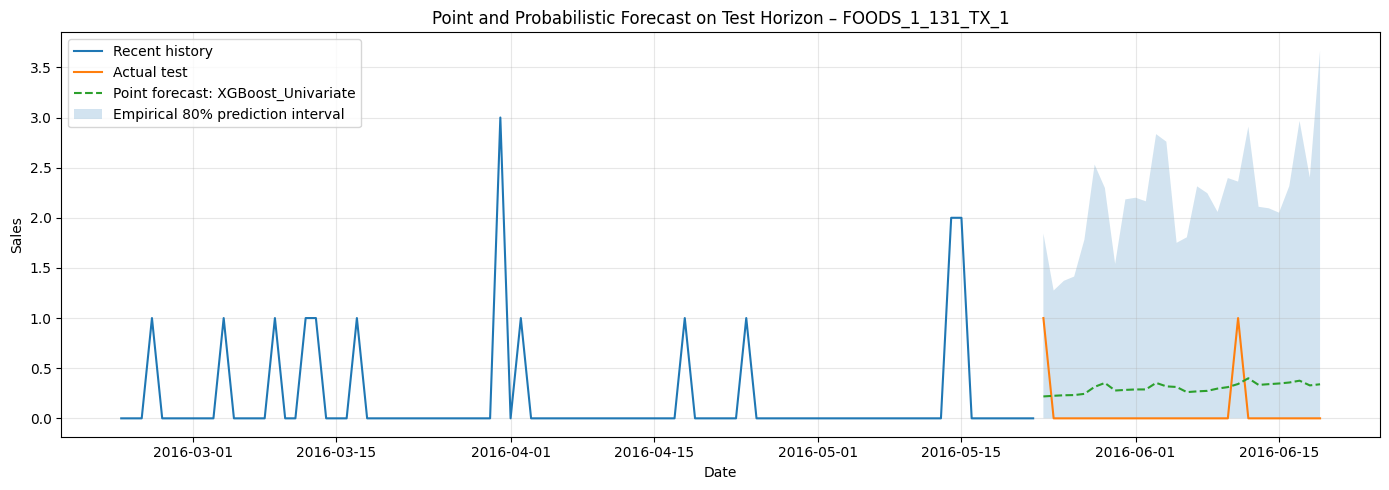

In [31]:
# Select a representative series for visual analysis.
# Preference: series with average demand close to the median, avoiding extremely sparse items.
series_mean_sales = train_plus_val.groupby("unique_id")["y"].mean().sort_values()
median_sales = series_mean_sales.median()
representative_id_test = (series_mean_sales - median_sales).abs().sort_values().index[0]

history_plot = train_plus_val[train_plus_val["unique_id"] == representative_id_test].tail(90)
actual_test_plot = test_eval_df[test_eval_df["unique_id"] == representative_id_test]

plt.figure(figsize=(14, 5))
plt.plot(history_plot["ds"], history_plot["y"], label="Recent history")
plt.plot(actual_test_plot["ds"], actual_test_plot["y"], label="Actual test")
plt.plot(
    actual_test_plot["ds"],
    actual_test_plot[best_ml_model],
    label=f"Point forecast: {best_ml_model}",
    linestyle="--"
)
plt.fill_between(
    actual_test_plot["ds"],
    actual_test_plot[f"{best_ml_model}_lo_80"],
    actual_test_plot[f"{best_ml_model}_hi_80"],
    alpha=0.2,
    label="Empirical 80% prediction interval"
)
plt.title(f"Point and Probabilistic Forecast on Test Horizon – {representative_id_test}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


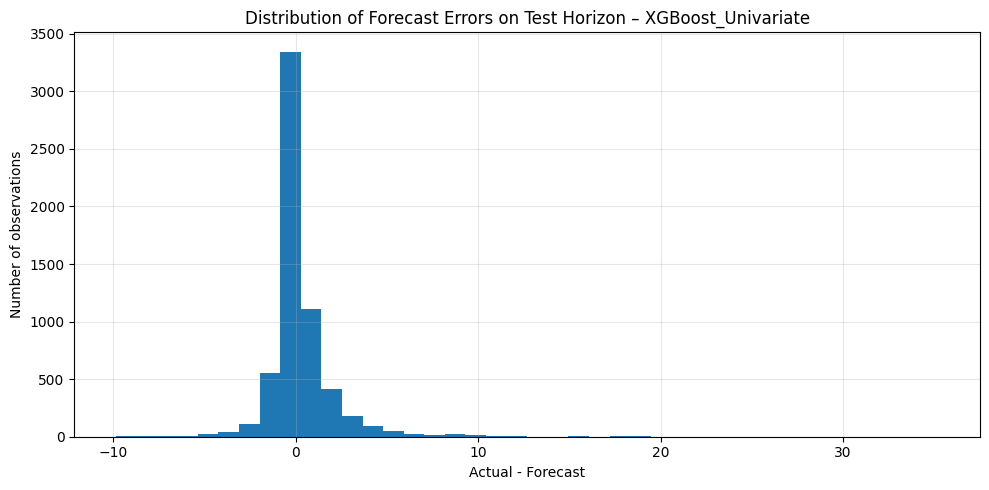

In [32]:
# Error distribution on the test horizon
plt.figure(figsize=(10, 5))
plt.hist(test_eval_df["error"].dropna(), bins=40)
plt.title(f"Distribution of Forecast Errors on Test Horizon – {best_ml_model}")
plt.xlabel("Actual - Forecast")
plt.ylabel("Number of observations")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation of the test forecast visualisation

The test plot provides a final visual check of the selected model's behaviour. The point forecast gives the expected demand, while the shaded interval represents empirical uncertainty based on validation residuals.

When actual sales fall inside the interval, the uncertainty estimate is behaving well. When actual sales fall outside the interval, the model is either underestimating or overestimating demand beyond what was observed in the validation residual distribution.

This visual inspection is important because it shows not only the average forecast accuracy, but also whether the model gives a realistic range of possible outcomes.

## 25. Comparison of Best ML Forecasts Against Best Phase 1 Model

The main comparison with Phase 1 is performed through RMSSE using the final statistical results. If point forecasts from Phase 1 are available, the notebook also overlays them with the best Machine Learning forecasts.

This visual comparison is useful because two models can have similar RMSSE values but behave differently. One model may capture the average level better, while another may react better to short-term fluctuations or demand peaks.

Loaded Phase 1 forecasts from: autoarima_forecasts_val.csv
Columns: ['index_x', 'unique_id', 'ds', 'AutoARIMA', 'AutoARIMA-lo-95', 'AutoARIMA-lo-80', 'AutoARIMA-hi-80', 'AutoARIMA-hi-95', 'index_y', 'AutoARIMAX', 'AutoARIMAX-lo-95', 'AutoARIMAX-lo-80', 'AutoARIMAX-hi-80', 'AutoARIMAX-hi-95']
Selected Phase 1 model column: AutoARIMAX
Number of matching dates: 28


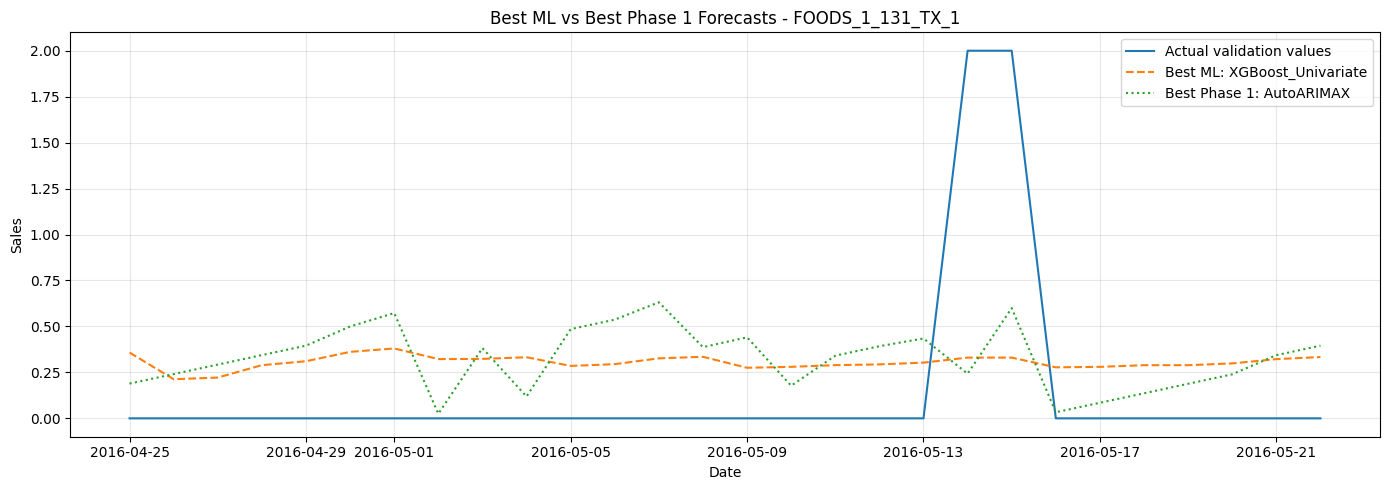

In [46]:

from google.colab import files

phase1_filename = "autoarima_forecasts_val.csv"

# If the file is not already available in the Colab session, ask the user to upload it
if not os.path.exists(phase1_filename):
    print("Please upload the Phase 1 forecast file: autoarima_forecasts_val.csv")
    uploaded = files.upload()

    if phase1_filename not in uploaded:
        raise FileNotFoundError(
            "The uploaded file must be named exactly: autoarima_forecasts_val.csv"
        )

# Load Phase 1 forecasts
phase1_forecasts = pd.read_csv(phase1_filename)
phase1_forecasts["ds"] = pd.to_datetime(phase1_forecasts["ds"])

print(f"Loaded Phase 1 forecasts from: {phase1_filename}")
print("Columns:", phase1_forecasts.columns.tolist())

# Identify the Phase 1 forecast column
possible_cols = [
    c for c in phase1_forecasts.columns
    if c not in ["unique_id", "ds", "y"]
]

if "AutoARIMAX" in possible_cols:
    phase1_model_col = "AutoARIMAX"
elif "AutoARIMA" in possible_cols:
    phase1_model_col = "AutoARIMA"
elif "ARIMAX" in possible_cols:
    phase1_model_col = "ARIMAX"
else:
    phase1_model_col = possible_cols[0] if len(possible_cols) > 0 else None

print("Selected Phase 1 model column:", phase1_model_col)

if phase1_model_col is None:
    raise ValueError("No valid forecast column was found in the Phase 1 forecast file.")

# If representative_id_test does not exist, select a valid series from the Phase 1 file
if "representative_id_test" not in globals():
    representative_id_test = phase1_forecasts["unique_id"].iloc[0]

# Get Phase 1 forecasts for the representative series
p1_plot = phase1_forecasts[
    phase1_forecasts["unique_id"] == representative_id_test
].copy()

# Actual validation values
actual_plot = val[
    val["unique_id"] == representative_id_test
][["ds", "y"]].copy()

# Get best ML validation forecasts
if "best_forecasts" not in globals():
    best_forecasts = get_validation_forecasts_for_model(best_ml_model)

ml_plot = best_forecasts[
    best_forecasts["unique_id"] == representative_id_test
][["ds", best_ml_model]].copy()

# Merge actual values, ML forecasts and Phase 1 forecasts
plot_df = (
    actual_plot
    .merge(ml_plot, on="ds", how="inner")
    .merge(p1_plot[["ds", phase1_model_col]], on="ds", how="inner")
    .sort_values("ds")
)

print("Number of matching dates:", len(plot_df))

if len(plot_df) == 0:
    raise ValueError(
        "No matching dates were found. "
        "Check if autoarima_forecasts_val.csv uses the same validation dates and unique_id."
    )

# Plot comparison
plt.figure(figsize=(14, 5))

plt.plot(
    plot_df["ds"],
    plot_df["y"],
    label="Actual validation values"
)

plt.plot(
    plot_df["ds"],
    plot_df[best_ml_model],
    linestyle="--",
    label=f"Best ML: {best_ml_model}"
)

plt.plot(
    plot_df["ds"],
    plot_df[phase1_model_col],
    linestyle=":",
    label=f"Best Phase 1: {phase1_model_col}"
)

plt.title(f"Best ML vs Best Phase 1 Forecasts - {representative_id_test}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Note on Phase 1 forecast overlay

The notebook attempted to load the Phase 1 point forecast file (`autoarima_forecasts_val.csv`) for a direct visual overlay. In this execution, that file was not available in the Colab environment, so the visual overlay could not be produced.

This does not invalidate the Phase 1 comparison, because the metric-based comparison is already performed using the final Phase 1 results table. However, if the forecast CSV is uploaded later, this cell can be re-run to add the visual comparison between AutoARIMAX and the best Machine Learning model.

## 26. Export Results

The final outputs are exported so they can be used in the written report and compared with Phase 1.

The exported files include the Machine Learning leaderboard, the comparison with Phase 1, the impact of exogenous regressors, the cross-validation summary and the final point/probabilistic forecasts. These outputs make the notebook reproducible and provide the numerical evidence needed for the project report.

In [34]:
all_ml_results.to_csv("ml_results.csv", index=False)
uni_results_df.to_csv("ml_univariate_results.csv", index=False)
exog_impact.to_csv("exogenous_regressor_impact.csv", index=False)
fcst_val_ml.to_csv("ml_forecasts_val_exogenous.csv", index=False)
fcst_val_uni.to_csv("ml_forecasts_val_univariate.csv", index=False)
fcst_val_lgb_diff.to_csv("ml_lgb_diff_forecasts_val.csv", index=False)
final_comparison.to_csv("final_results_with_machine_learning.csv", index=False)
test_forecasts.to_csv("best_ml_test_point_forecasts.csv", index=False)
test_forecasts_prob.to_csv("best_ml_test_probabilistic_forecasts.csv", index=False)
best_by_series.to_csv("best_ml_by_series_errors.csv", index=False)
test_eval_df.to_csv("best_ml_test_actual_vs_forecast.csv", index=False)

if "cv_overall" in globals() and not cv_overall.empty:
    cv_overall.to_csv("time_series_cross_validation_summary.csv", index=False)
    cv_summary.to_csv("time_series_cross_validation_by_window.csv", index=False)

# Export to Google Drive when available
try:
    all_ml_results.to_csv(f"{BASE_PATH}/ml_results.csv", index=False)
    uni_results_df.to_csv(f"{BASE_PATH}/ml_univariate_results.csv", index=False)
    exog_impact.to_csv(f"{BASE_PATH}/exogenous_regressor_impact.csv", index=False)
    fcst_val_ml.to_csv(f"{BASE_PATH}/ml_forecasts_val_exogenous.csv", index=False)
    fcst_val_uni.to_csv(f"{BASE_PATH}/ml_forecasts_val_univariate.csv", index=False)
    fcst_val_lgb_diff.to_csv(f"{BASE_PATH}/ml_lgb_diff_forecasts_val.csv", index=False)
    final_comparison.to_csv(f"{BASE_PATH}/final_results_with_machine_learning.csv", index=False)
    test_forecasts.to_csv(f"{BASE_PATH}/best_ml_test_point_forecasts.csv", index=False)
    test_forecasts_prob.to_csv(f"{BASE_PATH}/best_ml_test_probabilistic_forecasts.csv", index=False)
    best_by_series.to_csv(f"{BASE_PATH}/best_ml_by_series_errors.csv", index=False)
    test_eval_df.to_csv(f"{BASE_PATH}/best_ml_test_actual_vs_forecast.csv", index=False)
    if "cv_overall" in globals() and not cv_overall.empty:
        cv_overall.to_csv(f"{BASE_PATH}/time_series_cross_validation_summary.csv", index=False)
        cv_summary.to_csv(f"{BASE_PATH}/time_series_cross_validation_by_window.csv", index=False)
    print(f"Files also saved to: {BASE_PATH}")
except Exception as e:
    print("Files were saved locally. Google Drive export was skipped:", e)

print("Files exported successfully.")


Files also saved to: /content/drive/MyDrive/M5_Forecasting_Project
Files exported successfully.


### Export interpretation

The notebook exports all key tables required for the final report. These files allow the results to be reused without re-running the full notebook.

The most important exported outputs are the final ML leaderboard, the comparison with Phase 1, the exogenous regressor impact table, the cross-validation summary and the final point/probabilistic forecast table. Together, these files document both the model selection process and the final forecasting outputs.

## 27. Interpretation and Final Conclusion

This notebook completes Phase 2 of the forecasting project by applying Machine Learning methods to the same M5 department–store panel used in Phase 1: FOODS_1 in TX_1. The evaluation setup is kept consistent across phases, with a 28-day forecasting horizon and RMSSE as the main metric. This makes the final comparison fair and directly interpretable.

The Machine Learning workflow transforms the original time series into a supervised learning problem. The most relevant predictors are lagged sales, rolling averages and calendar features. These variables allow the models to learn recent demand behaviour, weekly patterns and broader seasonal effects. The notebook also tests the contribution of exogenous regressors, including selling prices, SNAP indicators and event variables.

The main Machine Learning experiment shows that XGBoost is the best model when exogenous variables are included, with an RMSSE of 0.7501. However, the best overall Machine Learning result is obtained by XGBoost_Univariate, with an RMSSE of 0.7498. This means that, for this specific subset, the historical sales pattern is more informative than the additional external variables.

The comparison between univariate and exogenous versions shows a mixed impact. ExtraTrees and LightGBM improve slightly when exogenous regressors are added, but XGBoost, RandomForest, Ridge and LinearRegression perform marginally better without them. The differences are small, so the most appropriate conclusion is that exogenous variables have limited and model-dependent value in this validation period.
This behaviour can also be explained by the nature of the FOODS_1 category. In grocery retail, demand is often driven by habitual consumption patterns and weekly routines rather than strong reactions to price changes or external events. As a result, historical sales (lags and rolling statistics) tend to be more informative than exogenous variables, which may have limited variability or weak direct impact on demand.

The advanced differenced LightGBM experiment performs poorly, with an RMSSE of 0.9993. This suggests that target differencing is not suitable for this dataset, probably because several product-level series contain intermittent demand and many zero-sales periods. In this context, differencing can remove useful level information rather than improve the forecast.

The cross-validation section supports the robustness of the modelling approach. LightGBM with exogenous regressors obtains an average RMSSE of 0.7389, while the univariate version obtains 0.7400. The difference is very small, again reinforcing that external variables may help slightly in some periods but are not the dominant source of predictive power.

In the final comparison with Phase 1, the best overall model is still AutoARIMAX, with an RMSSE of 0.7443. The best Machine Learning model, XGBoost_Univariate, obtains 0.7498, which is approximately 0.74% worse than AutoARIMAX on the main metric.
This difference is marginal and can be considered negligible in practical settings, where model selection is often influenced not only by accuracy but also by scalability, computational efficiency and ease of deployment.
This result also highlights an important principle in time series forecasting: increased model complexity does not necessarily lead to better performance. In datasets with noise, intermittency or weak exogenous signals, simpler statistical models such as ARIMAX can remain more robust and generalisable than more flexible Machine Learning approaches, which may be more prone to overfitting short-term fluctuations.
Therefore, Phase 2 does not clearly outperform Phase 1, but it produces a very competitive Machine Learning alternative.

The feature importance analysis confirms the interpretation of the results. The most important predictor is the 7-day rolling mean based on the most recent lag, with an importance of 0.4643. This shows that recent demand behaviour is the strongest driver of the forecast. Other lag and rolling features also dominate the ranking, while calendar variables have a smaller contribution.

The final test analysis shows that the selected model obtains a Test MAE of 1.0602 and a Test RMSE of 1.9333. The empirical 80% prediction interval achieves 77.22% coverage, which is close to the intended level. This indicates that the probabilistic forecasts provide a reasonable approximation of uncertainty, although the intervals are slightly narrow.

Overall, the project satisfies the Phase 2 requirements. It includes several Machine Learning models, compares univariate and exogenous versions, applies time-series cross-validation, generates point and probabilistic forecasts, analyses feature importance and compares the best Machine Learning model with the best Phase 1 statistical model. The final conclusion is that XGBoost_Univariate is the best Machine Learning model, while AutoARIMAX remains the best overall model according to RMSSE.